## Inicialización

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

## Cargar datos

El conjunto de datos se almacena en la carpeta `/datasets/faces/`
- La carpeta `final_files` con 7600 fotos
- El archivo `labels.csv` con leyendas, con dos columnas: `file_name` y `real_age`

Dado que el número de archivos de imágenes es bastante elevado, se recomienda evitar leerlos todos a la vez, ya que esto consumiría muchos recursos computacionales. Te recomendamos crear un generador con ImageDataGenerator. Este método se explicó en el capítulo 3, lección 7 de este curso.

El archivo de etiqueta se puede cargar como un archivo CSV habitual.

In [2]:
# Configuraciones
%config InlineBackend.figure_format = 'retina'
plt.style.use('seaborn-v0_8')

In [3]:
labels = pd.read_csv('datasets/faces/labels.csv')

labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  7591 non-null   str  
 1   real_age   7591 non-null   int64
dtypes: int64(1), str(1)
memory usage: 118.7 KB


In [4]:
labels.sample(10)

,file_name,real_age
3095,003095.jpg,51
7071,007085.jpg,66
1141,001141.jpg,1
4460,004460.jpg,44
4341,004341.jpg,7
7262,007280.jpg,33
1465,001465.jpg,6
4338,004338.jpg,13
1955,001955.jpg,24
5946,005947.jpg,41


## EDA

## Tamaño del conjunto de datos

In [5]:
print(f'Fotos totales {labels.shape[0]}')

Fotos totales 7591


## Distribución de edad en el conjunto de datos

Veremos la cantidad de fotos por edad

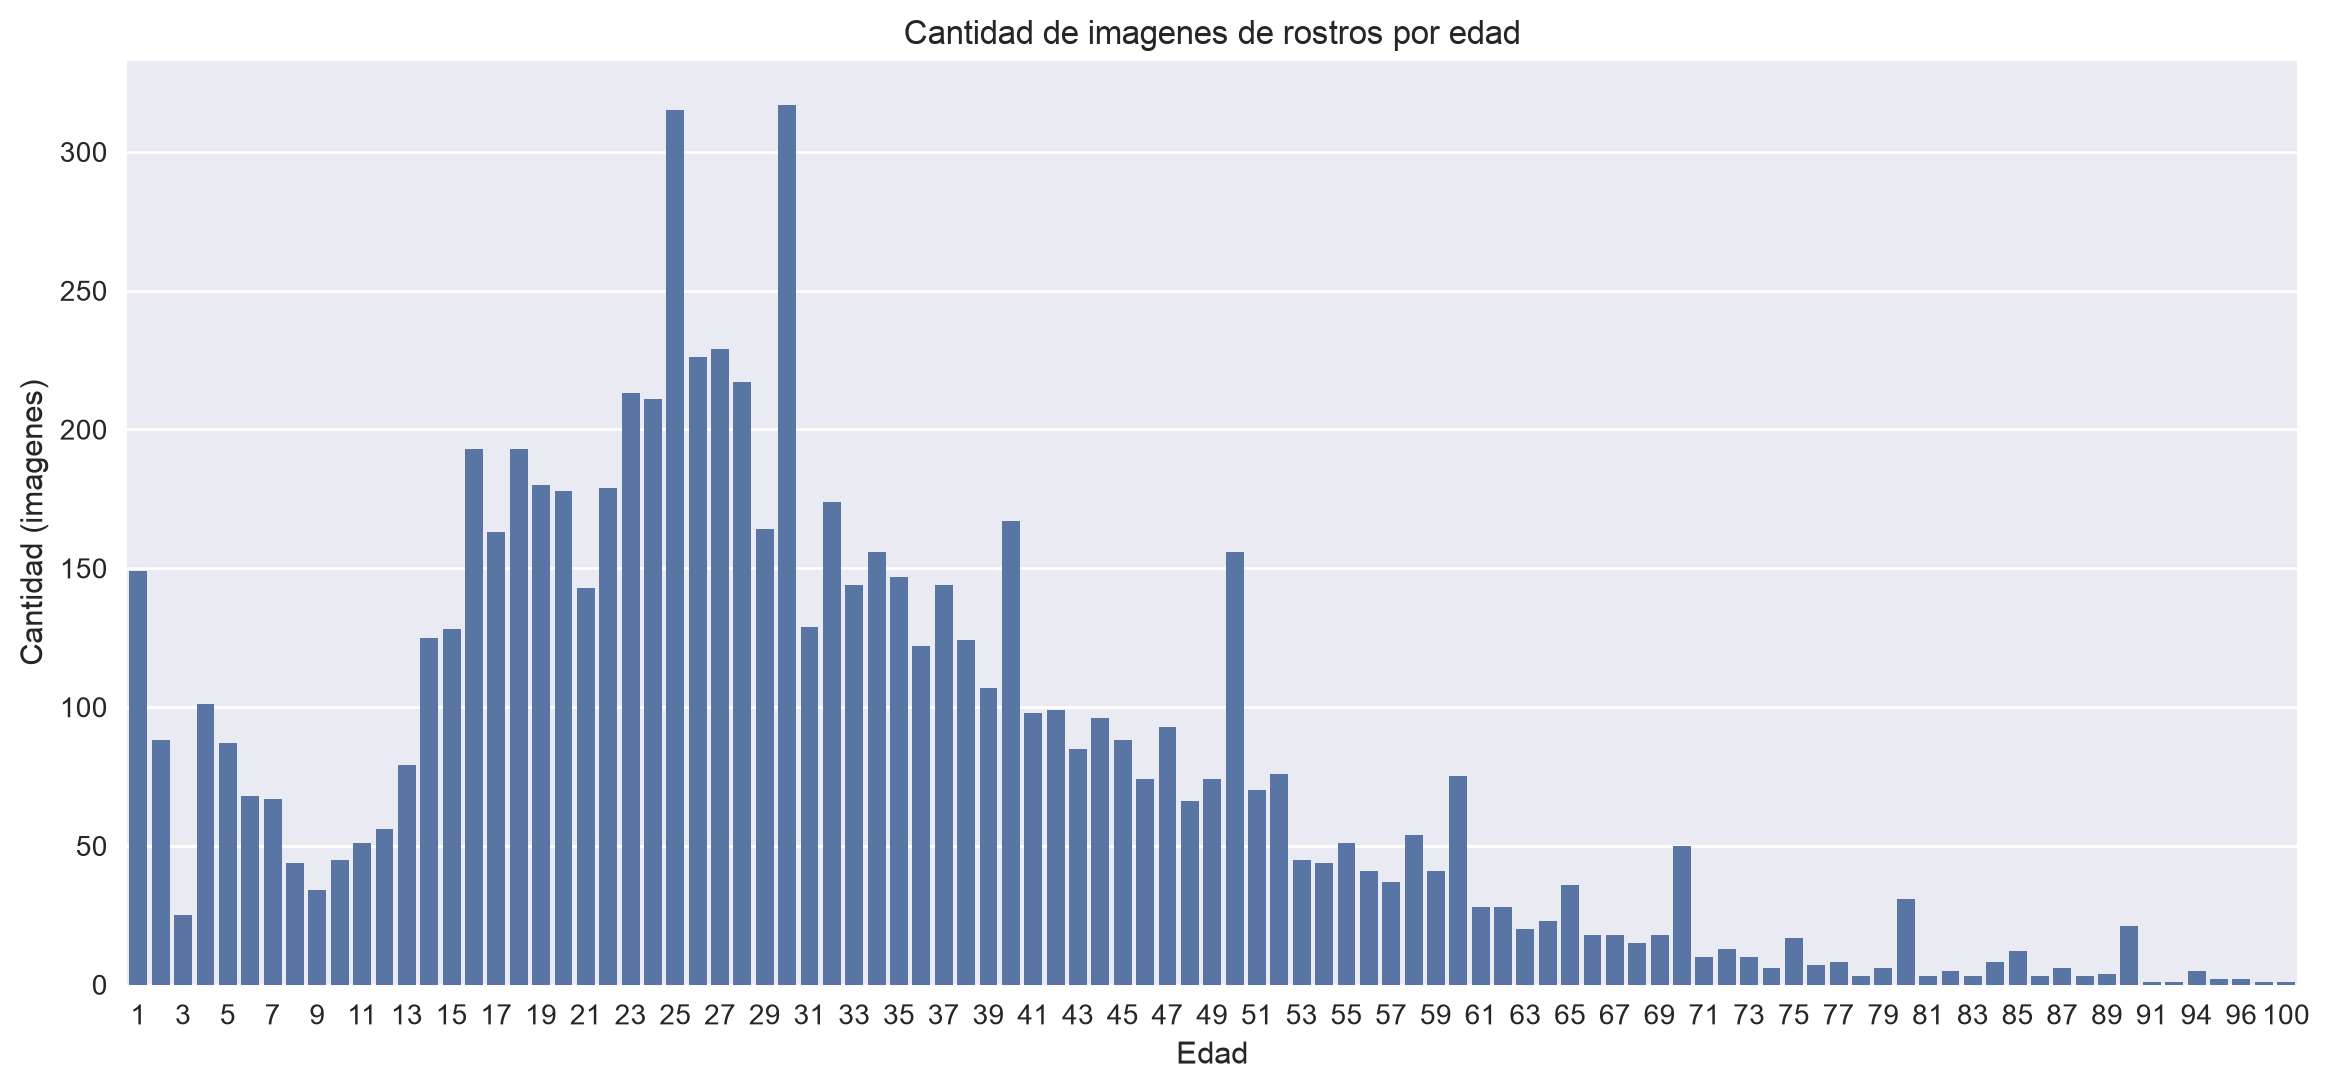

In [6]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(data=labels, x='real_age')

plt.title('Cantidad de imagenes de rostros por edad')
plt.ylabel('Cantidad (imagenes)')
plt.xlabel('Edad')

locs, labels_x = plt.xticks()
plt.xticks(locs[::2], [l.get_text() for l in labels_x[::2]])

plt.show()

## 15 fotos de personas

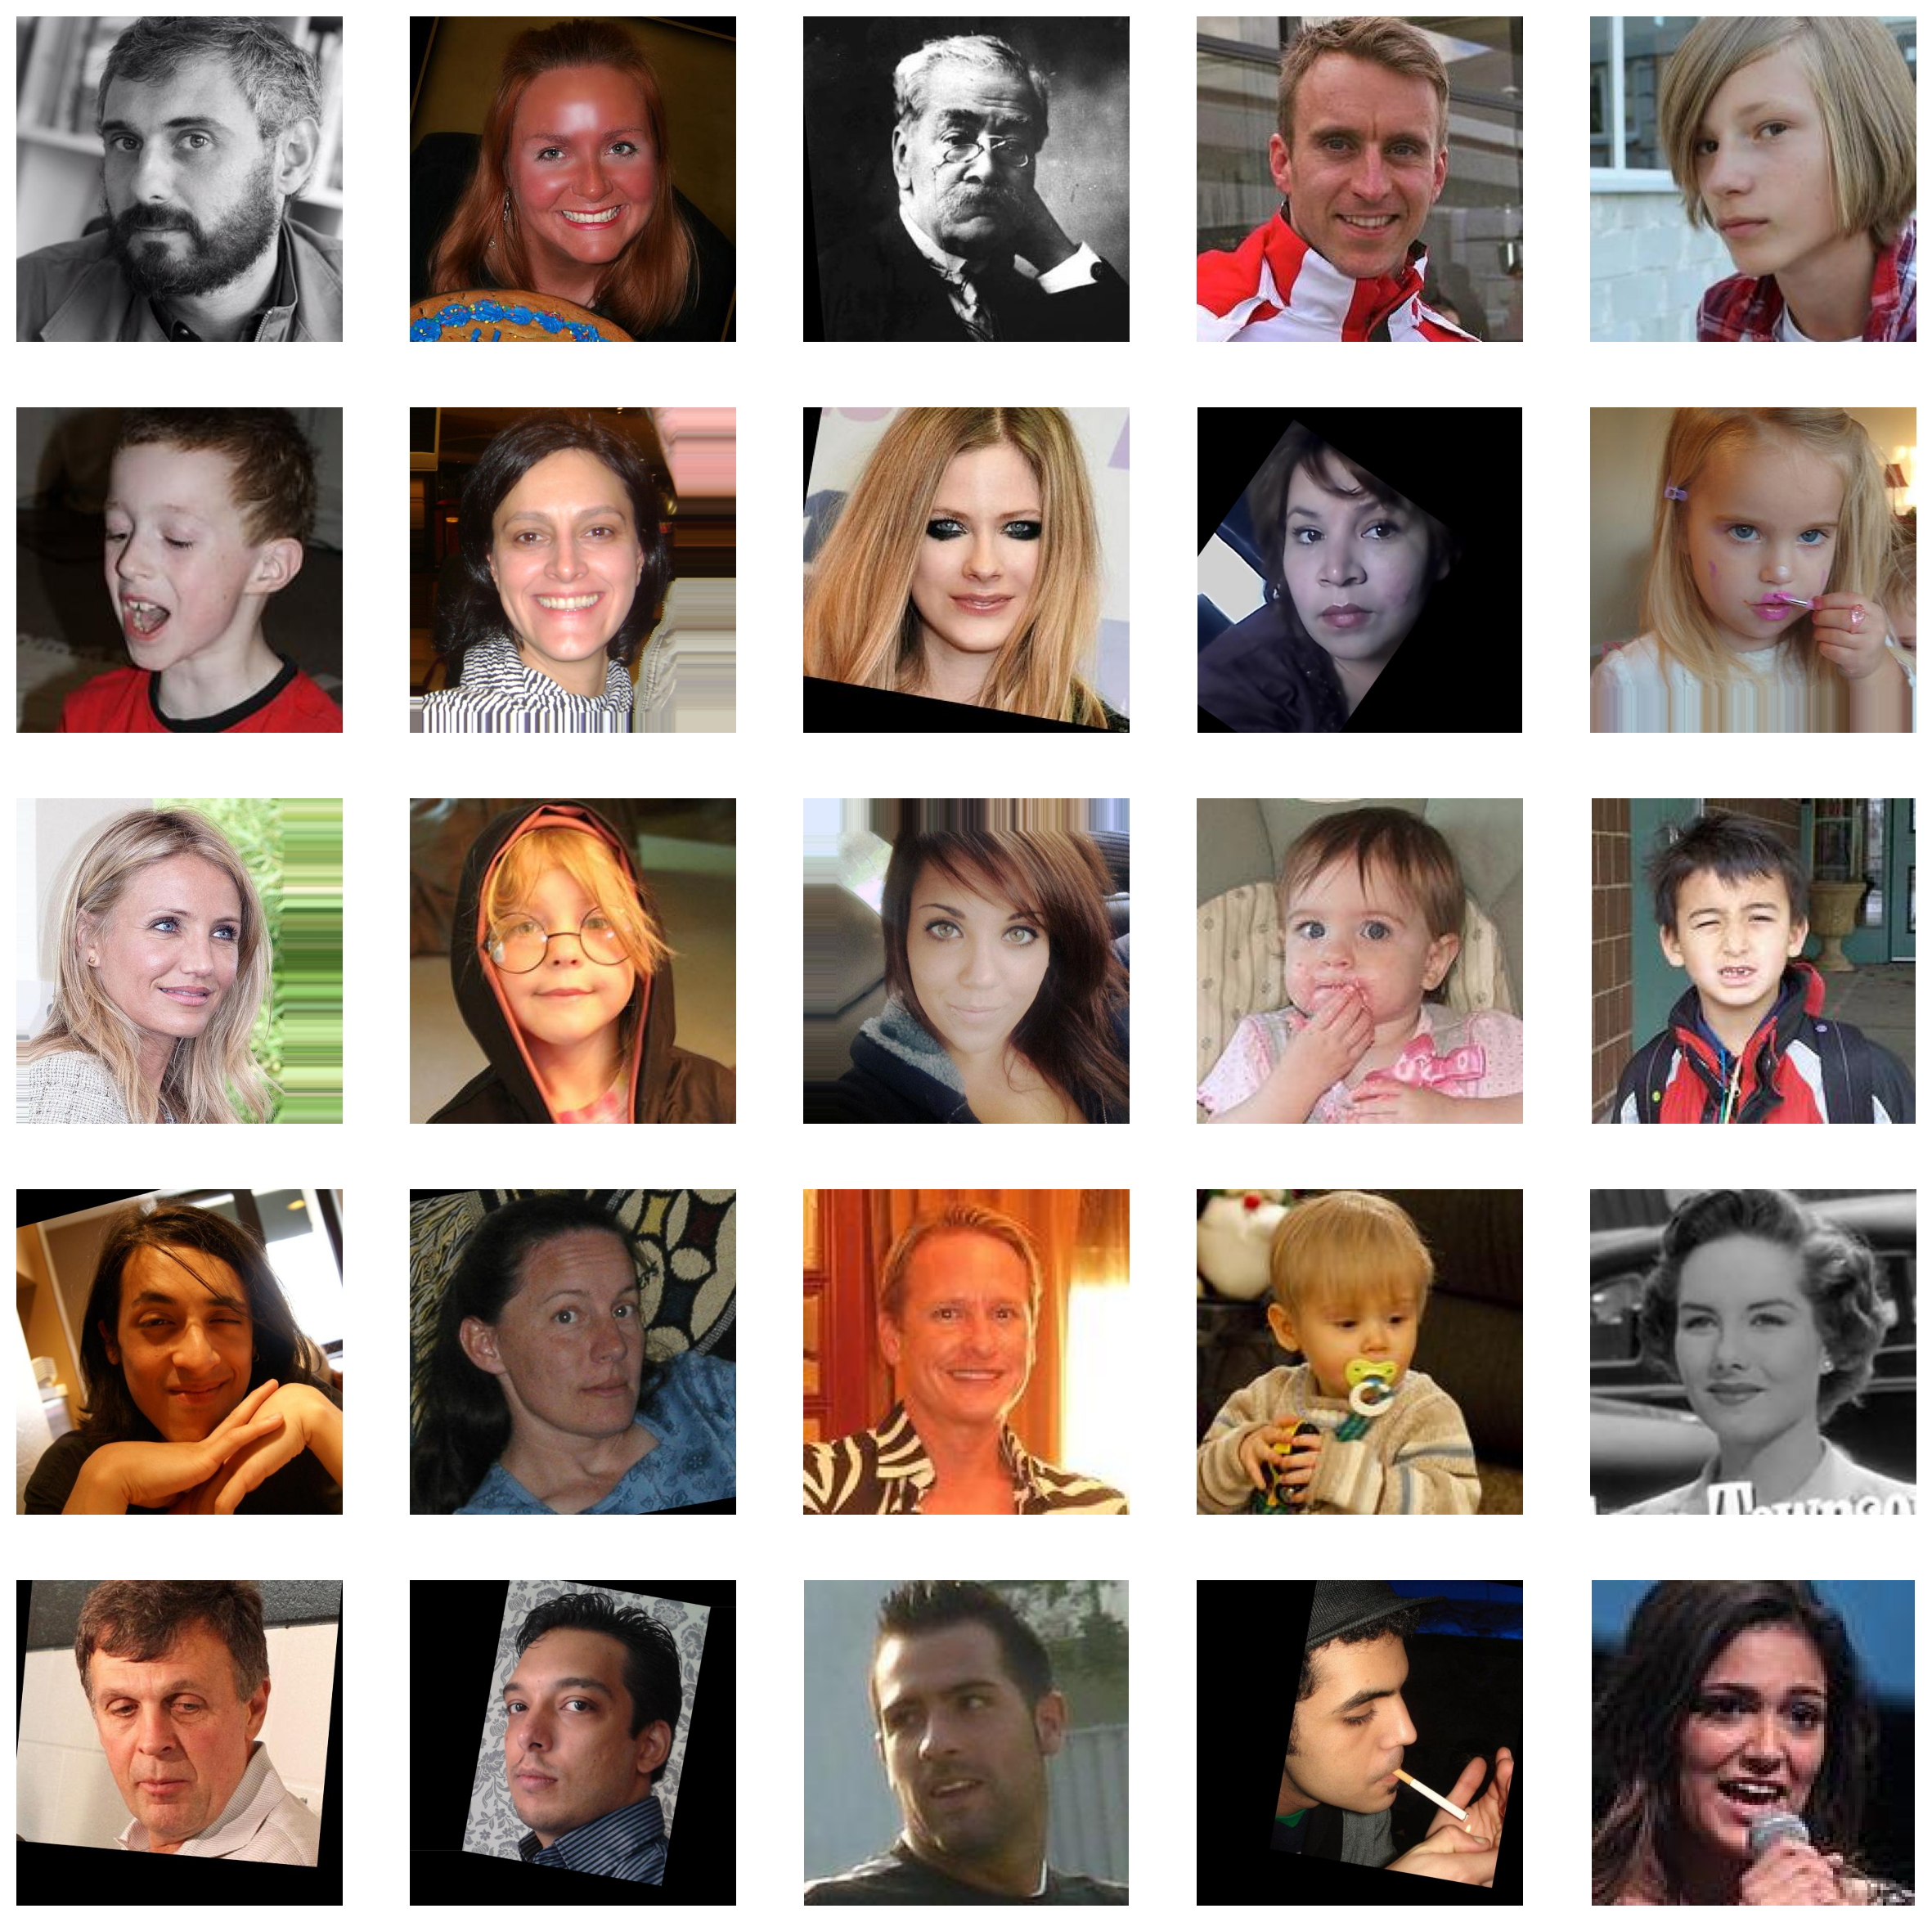

In [7]:
images_names = labels.sample(25).reset_index()

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for ax, (_, row) in zip(axes.flat, images_names.iterrows()):
        image_path = f"datasets/faces/final_files/{row['file_name']}"
        image = Image.open(image_path)
        array = np.array(image)
        ax.imshow(array)
        ax.grid(False)
        ax.axis('off')

plt.show()

### Conclusiones

Se cuenta con cerca de 7600 imagenes de personas de entre 1 y 100 años. También se puede ver que las edades no cuentan con un número equitativo de imagenes. Las edades de 25 y 30 años son las que más imagenes tienen. Realmente se tiene fotos de personas en diferentes angulo y características.

## Modelado

Define las funciones necesarias para entrenar tu modelo en la plataforma GPU y crear un solo script que las contenga todas junto con la sección de inicialización.

Para facilitar esta tarea, puedes definirlas en este notebook y ejecutar un código listo en la siguiente sección para componer automáticamente el script.

Los revisores del proyecto también verificarán las definiciones a continuación, para que puedan comprender cómo construiste el modelo.

In [8]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [9]:
def load_train(path, labels):
    
    """
    Carga la parte de entrenamiento del conjunto de datos desde la ruta.
    """
    
    train_datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1/255,
        horizontal_flip=True,
        vertical_flip=True,
        rotation_range=90,
        width_shift_range=.20,
        height_shift_range=.20
    )

    train_gen_flow = train_datagen.flow_from_dataframe(
        labels,
        directory=path,
        x_col='file_name',
        y_col='real_age',
        class_mode='raw',
        target_size=(224, 224),
        batch_size=32,
        subset='training',
        seed=42
    )

    return train_gen_flow

In [10]:
def load_test(path, labels):
    
    """
    Carga la parte de validación/prueba del conjunto de datos desde la ruta
    """
    
    test_datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1/255
    )

    test_gen_flow = test_datagen.flow_from_dataframe(
        labels,
        directory=path,
        x_col='file_name',
        y_col='real_age',
        class_mode='raw',
        target_size=(224, 224),
        batch_size=32,
        subset='validation',
        seed=42
    )

    return test_gen_flow

In [11]:
def create_model(input_shape):
    
    """
    Define el modelo
    """

    backbone = ResNet50(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    
    model = Sequential()

    model.add(backbone)

    model.add(GlobalAveragePooling2D())

    model.add(Dense(units=1, activation='relu'))

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        loss='mae',
        optimizer=optimizer,
        metrics=['acc']
    )

    return model

In [12]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20):

    """
    Entrena el modelo dados los parámetros
    """
    
    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        verbose=1
    )

    return model

In [ ]:
# Parametros
width = 224
height = 224
batch_size = 32
input_shape = (width, height, 3)

path_train = 'datasets/faces/final_files/'
path_val = 'datasets/faces/final_files/'
labels_path = 'datasets/faces/labels.csv'

# Cargar labels
labels = pd.read_csv(labels_path)

# Carga los datos de entrenamiento y validación
train_gen = load_train(path_train, labels=labels)
val_gen = load_test(path_val, labels=labels)

# Crea y entrena el modelo simple
model = create_model(input_shape)
trained_model = train_model(model, train_gen, val_gen, batch_size=batch_size, epochs=10)

### Prepara el script para ejecutarlo en la plataforma GPU

Una vez que hayas definido las funciones necesarias, puedes redactar un script para la plataforma GPU, descargarlo a través del menú "File|Open..." (Archivo|Abrir) y cargarlo más tarde para ejecutarlo en la plataforma GPU.

Nota: el script debe incluir también la sección de inicialización. A continuación se muestra un ejemplo.

In [13]:
# prepara un script para ejecutarlo en la plataforma GPU

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

### Resultado

Coloca aquí el resultado de la plataforma GPU como una celda Markdown.

WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1786206360.716979   39411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786206360.749285   39411 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1786206361.497964   39411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Found 5694 validated image filenames.
Found 1897 validated image filenames.
I0000 00:00:1786206362.055649   39411 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:01:00.0, compute capability: 8.9
Epoch 1/10
I0000 00:00:1786206363.687892   39411 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1786206375.313528   39510 service.cc:153] XLA service 0x70d9fc041e10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1786206375.313566   39510 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.3.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1786206375.669304   39510 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1786206377.939712   39510 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1786206395.403018   39510 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
178/178 - 86s - 484ms/step - acc: 0.0176 - loss: 12.8108 - val_acc: 0.0237 - val_loss: 21.9914
Epoch 2/10
178/178 - 30s - 170ms/step - acc: 0.0172 - loss: 9.4127 - val_acc: 0.0237 - val_loss: 23.9311
Epoch 3/10
178/178 - 31s - 172ms/step - acc: 0.0163 - loss: 8.9002 - val_acc: 0.0237 - val_loss: 12.9935
Epoch 4/10
178/178 - 30s - 170ms/step - acc: 0.0169 - loss: 8.4251 - val_acc: 0.0237 - val_loss: 9.7059
Epoch 5/10
178/178 - 31s - 172ms/step - acc: 0.0176 - loss: 8.1320 - val_acc: 0.0206 - val_loss: 10.6232
Epoch 6/10
178/178 - 31s - 176ms/step - acc: 0.0172 - loss: 7.8273 - val_acc: 0.0163 - val_loss: 7.7518
Epoch 7/10
178/178 - 30s - 170ms/step - acc: 0.0163 - loss: 7.7339 - val_acc: 0.0179 - val_loss: 7.4810
Epoch 8/10
178/178 - 30s - 169ms/step - acc: 0.0169 - loss: 7.5351 - val_acc: 0.0042 - val_loss: 8.0080
Epoch 9/10
178/178 - 31s - 173ms/step - acc: 0.0167 - loss: 7.3966 - val_acc: 0.0163 - val_loss: 10.7100
Epoch 10/10
178/178 - 32s - 177ms/step - acc: 0.0165 - loss: 7.3488 - val_acc: 0.0232 - val_loss: 8.7006

## Conclusiones

- Se obtuvo el valor eam del modelo dentro del umbral para este proyecto.

- Se puede observar también que a partir de la epoca 7 la métrica MAE no disminuye, si no incrementa, es el momento en el que el modelo comienza sobreajustarse al conjunto de entrenamiento. Yo me quedaría con 7 epocas para el modelo.

- Finalmente, al comparar la cpu y la GPU si se puede observar una diferencia en cuanto a la velocidad.

- En este caso podría ser dificil que ayude al cliente, pero se podría tomar algunas medidas para que el modelo llegue a producción. El modelo se equivoca 7.4810 años para arriva y para abajo (redondenadolo 8), por lo que podría vender alcohol a personas que obtengan una edad por medio del modelo de 18 + 8 años = 26 y a los que se encuentran en el rango de 18 a 26 años solucidad identificación.

- Otras tareas en las que este modelo podría se aplicable, se me ocurre un conteo de las edades que visitan la tienda, con esta información ajustar los productos de enfrente en cuestion de los clientes más frecuentes.

# Lista de revisión

- [x]  El Notebook estaba abierto 
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución
- [x]  Se realizó el análisis exploratorio de datos
- [x]  Los resultados del análisis exploratorio de datos se presentan en el notebook final
- [x]  El valor EAM del modelo no es superior a 8
- [x]  El código de entrenamiento del modelo se copió en el notebook final
- [x]  El resultado de entrenamiento del modelo se copió en el notebook final
- [x]  Los hallazgos se proporcionaron con base en los resultados del entrenamiento del modelo